# 04 - Baseline Models: Logistic Regression, Random Forest, XGBoost

Predict 30-day hospital readmission (`readmit_30`) with three standard baselines, to compare against the MLP (`02`) and Kumo-Tabular (`03`) notebooks.

## Design choices and rationale

**Why these three models.** They cover three different model families on tabular data: a linear model (interpretable, a floor for what the features alone can do), a bagged tree ensemble (captures interactions with little tuning), and gradient-boosted trees (usually the strongest on tabular data). If the MLP cannot beat them, that is itself a finding.

**Same protocol as the MLP notebook.** A comparison is only meaningful if every model sees the same data and is scored the same way:
- Same files (`train_clean.csv`, `test_clean.csv`) from the cleaning pipeline.
- Same 80/20 stratified validation split of the training file, `random_state=42`. Stratifying keeps the ~9% positive rate equal in each part.
- The test set is used once, at the end. Nothing (threshold, early stopping, hyperparameters) is chosen on it.

**Imbalance handling: class weights, not resampling.** Only ~9% of encounters are readmitted within 30 days. Weighting the loss (`class_weight='balanced'`, `'balanced_subsample'`, `scale_pos_weight`) is the same approach the MLP used. It avoids SMOTE or undersampling, which would change the training distribution and add another variable to the comparison. Probabilities from weighted models are shifted upward, which is why the threshold is tuned below rather than fixed at 0.5.

**Metrics.** With a ~9% positive rate, accuracy is misleading (predicting "no" for everyone scores ~91%). PR-AUC is the headline metric because it reflects the minority class directly. ROC-AUC is reported for comparability with the other notebooks. Precision, recall and F1 are reported at a chosen threshold, since a clinical use case cares about how many true readmissions are caught and at what false-alarm cost.

### Data and split

Scaling is fit on the training portion only, then applied to validation and test, so no information leaks from held-out data. The scaled copy is used by logistic regression only. Tree models are invariant to monotonic feature scaling, so they get the raw features.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_curve)

SEED, TARGET = 42, "readmit_30"
DATA = "../data/processed" if os.path.exists("../data/processed") else "data/processed"
RESULTS = "../results" if os.path.exists("../results") else "results"

train_df = pd.read_csv(f"{DATA}/train_clean.csv")
test_df = pd.read_csv(f"{DATA}/test_clean.csv")

X = train_df.drop(columns=[TARGET]); y = train_df[TARGET]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
X_test, y_test = test_df.drop(columns=[TARGET]), test_df[TARGET]

scaler = StandardScaler().fit(X_train)           # used by logistic regression only
Xs_train, Xs_val, Xs_test = (scaler.transform(a) for a in (X_train, X_val, X_test))

print(X_train.shape, X_val.shape, X_test.shape)
print("Prevalence train/val/test:", round(y_train.mean(),4), round(y_val.mean(),4), round(y_test.mean(),4))

(44780, 133) (11196, 133) (13994, 133)
Prevalence train/val/test: 0.0897 0.0897 0.0897


## Models and hyperparameters

Hyperparameters are fixed, conventional values. **No hyperparameter search was run.** The aim is a fair baseline, not the best possible score for each model, and searching only some models would bias the comparison.

| Model | Key settings | Why |
|---|---|---|
| Logistic Regression | `C=1.0` (L2), `lbfgs`, `max_iter=2000`, balanced weights, scaled inputs | Default regularisation is a reasonable prior for ~130 mostly one-hot features. Scaling is needed so the penalty treats features equally and the solver converges. |
| Random Forest | 500 trees, `min_samples_leaf=5`, `max_features='sqrt'`, `balanced_subsample` | 500 trees is enough for stable estimates. A leaf size of 5 stops fully grown trees from memorising noise on a noisy, weak-signal target. `balanced_subsample` recomputes weights per bootstrap sample. |
| XGBoost | `learning_rate=0.05`, `max_depth=4`, `subsample=0.8`, `colsample_bytree=0.8`, `min_child_weight=5`, `scale_pos_weight = neg/pos`, up to 1000 rounds with early stopping (50) on validation PR-AUC | Shallow trees, a low learning rate and row/column subsampling are standard regularisation for a noisy target. Early stopping picks the number of trees from validation data, so it is not hand-set. It monitors PR-AUC to match the headline metric. |

All models use `random_state=42`.

In [2]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": (LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000,
                                               solver="lbfgs", random_state=SEED), True),
    "Random Forest": (RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                                             class_weight="balanced_subsample", n_jobs=-1,
                                             random_state=SEED), False),
    "XGBoost": (XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4, subsample=0.8,
                              colsample_bytree=0.8, min_child_weight=5, scale_pos_weight=neg/pos,
                              eval_metric="aucpr", early_stopping_rounds=50, n_jobs=-1,
                              random_state=SEED), False),
}

val_probs, test_probs, fitted = {}, {}, {}
for name, (m, scaled) in models.items():
    Xtr, Xv, Xt = (Xs_train, Xs_val, Xs_test) if scaled else (X_train, X_val, X_test)
    if name == "XGBoost":
        m.fit(Xtr, y_train, eval_set=[(Xv, y_val)], verbose=False)
        print("XGBoost best iteration:", m.best_iteration)
    else:
        m.fit(Xtr, y_train)
    val_probs[name], test_probs[name] = m.predict_proba(Xv)[:, 1], m.predict_proba(Xt)[:, 1]
    fitted[name] = m
    print("fitted", name)

fitted Logistic Regression


fitted Random Forest


XGBoost best iteration: 23
fitted XGBoost


## Threshold selection and final test evaluation

Models output probabilities, and precision/recall/F1 depend on where we cut them. Each model's threshold is chosen **on the validation set** by scanning 0.05 to 0.95 and taking the maximum F1, then applied unchanged to the test set. This follows the MLP notebook and keeps the test set untouched.

Choosing a threshold per model matters here: the models' probabilities are calibrated very differently (see the 0.5 table below), so a shared fixed threshold would favour whichever model happens to be centred near it.

Maximising F1 is a neutral default. A hospital that prefers catching more readmissions would pick a lower threshold, trading precision for recall. Threshold-free metrics (PR-AUC, ROC-AUC) are unaffected by this choice and are the safer basis for ranking models.

In [3]:
def metrics(y_true, p, t):
    pred = (p >= t).astype(int)
    return {"PR-AUC": average_precision_score(y_true, p), "ROC-AUC": roc_auc_score(y_true, p),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0)}

grid = np.arange(0.05, 0.96, 0.01)
thr = {n: float(grid[np.argmax([f1_score(y_val, (p >= t).astype(int), zero_division=0) for t in grid])])
       for n, p in val_probs.items()}

val_rows = [{"Model": n, "Threshold": round(thr[n],2), **metrics(y_val, val_probs[n], thr[n])} for n in models]
test_rows = [{"Model": n, "Threshold": round(thr[n],2), **metrics(y_test, test_probs[n], thr[n])} for n in models]
val_df, test_df_res = pd.DataFrame(val_rows).round(4), pd.DataFrame(test_rows).round(4)
print("VALIDATION"); display(val_df)
print("TEST (final)"); display(test_df_res)

VALIDATION


,Model,Threshold,PR-AUC,ROC-AUC,Precision,Recall,F1
0,Logistic Regression,0.54,0.1546,0.6432,0.1464,0.4691,0.2232
1,Random Forest,0.33,0.1580,0.6531,0.1624,0.4253,0.2351
2,XGBoost,0.52,0.1547,0.6442,0.1523,0.4552,0.2282


TEST (final)


,Model,Threshold,PR-AUC,ROC-AUC,Precision,Recall,F1
0,Logistic Regression,0.54,0.1493,0.6354,0.1462,0.4494,0.2207
1,Random Forest,0.33,0.1568,0.6477,0.1583,0.4064,0.2278
2,XGBoost,0.52,0.1567,0.6420,0.1566,0.4598,0.2337


### Interpretation: test results

Test set: 13,994 encounters, 1,255 readmitted within 30 days (8.97%). Figures below are for the tuned thresholds.

**Overall level.** All three models rank patients only modestly better than chance (ROC-AUC 0.635 to 0.648, where 0.5 is chance). PR-AUC is 0.149 to 0.157 against a no-skill baseline of 0.090, so the models are about 1.7x better than random at the top of the ranking, but most flagged patients are still not readmitted.

**What that means in patients** (counts derived from the reported precision and recall):

| Model | Flagged | Readmissions caught | False alarms | Missed | Precision lift over 9% base rate |
|---|---|---|---|---|---|
| Logistic Regression | ~3,860 | ~564 (45%) | ~3,290 | ~691 | 1.63x |
| Random Forest | ~3,220 | ~510 (41%) | ~2,710 | ~745 | 1.77x |
| XGBoost | ~3,690 | ~577 (46%) | ~3,110 | ~678 | 1.75x |

Each model catches roughly 40 to 46% of readmissions but flags about 3,200 to 3,900 patients to do it. Roughly 84 to 85% of flagged patients are false alarms. Whether that is acceptable depends on the cost of the follow-up intervention. It could be reasonable for a cheap action such as a discharge phone call and too costly for an expensive one.

**Model comparison.**
- *Random Forest* has the best PR-AUC (0.157) and ROC-AUC (0.648), so it ranks patients best. At its F1-optimal threshold it flags fewer patients and has the highest precision, but the lowest recall.
- *XGBoost* has the best F1 (0.234) and recall (0.460) with nearly the same PR-AUC as Random Forest (0.1567 vs 0.1568). It is the best overall balance.
- *Logistic Regression* is lowest on every ranking metric (PR-AUC 0.149, ROC-AUC 0.635) but only by about 0.01 to 0.013. A plain linear model gets most of what the tree models get, so there is little non-linear structure that these features expose.
- These gaps are small relative to what one split and one seed can produce (see Limitations). The data support "the three are similar", not a strict ranking. XGBoost or Random Forest edging out logistic regression is plausible but unproven here.

**Validation vs test.** Test metrics are slightly below validation for every model (for example Logistic Regression PR-AUC 0.155 to 0.149, Random Forest ROC-AUC 0.653 to 0.648). The drop is small and consistent with mild optimism from choosing thresholds and early stopping on validation, not with serious overfitting.

**Versus the baseline MLP.** The MLP README reports ROC-AUC 0.642 and PR-AUC 0.158, which falls inside the range of these classical models. The neural network adds no clear gain over logistic regression on this feature set. Check the final regularized MLP's test numbers in `02` before stating this in the report, since the README figures may be validation or 0.5-threshold values.

### Results at the default 0.5 threshold

Shown because the baseline MLP README reports metrics at 0.5. Compare with the tuned table above to see how much of each model's precision/recall is a threshold effect rather than a ranking-quality difference. Random Forest is the clearest case: its averaged tree votes rarely exceed 0.5, so recall collapses at 0.5 even though its PR-AUC and ROC-AUC are the best of the three. Only compare models on F1/precision/recall at the same kind of threshold (tuned vs tuned).

In [4]:
default_df = pd.DataFrame([{"Model": n, **metrics(y_test, test_probs[n], 0.5)} for n in models]).round(4)
display(default_df)

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1
0,Logistic Regression,0.1493,0.6354,0.1339,0.5386,0.2145
1,Random Forest,0.1568,0.6477,0.2486,0.0717,0.1113
2,XGBoost,0.1567,0.6420,0.1364,0.5219,0.2163


### Interpretation: threshold effects

At 0.5, Logistic Regression and XGBoost flag many patients (recall 0.52 to 0.54, precision ~0.13 to 0.14), because class weighting pushes their probabilities up. Random Forest does the opposite: precision 0.25 but recall only 0.07, because its averaged tree votes rarely exceed 0.5. Its tuned threshold of 0.33 corrects this, and F1 rises from 0.11 to 0.23.

This shows why F1, precision and recall at a fixed 0.5 should not be used to rank these models. The threshold-free metrics (PR-AUC, ROC-AUC) put Random Forest first, while F1 at 0.5 puts it last.

## Plots

PR and ROC curves are drawn on the test set and show performance across all thresholds, independent of the F1 choice. The dashed line on the PR plot is the no-skill baseline (the positive rate). Confusion matrices use each model's tuned threshold.

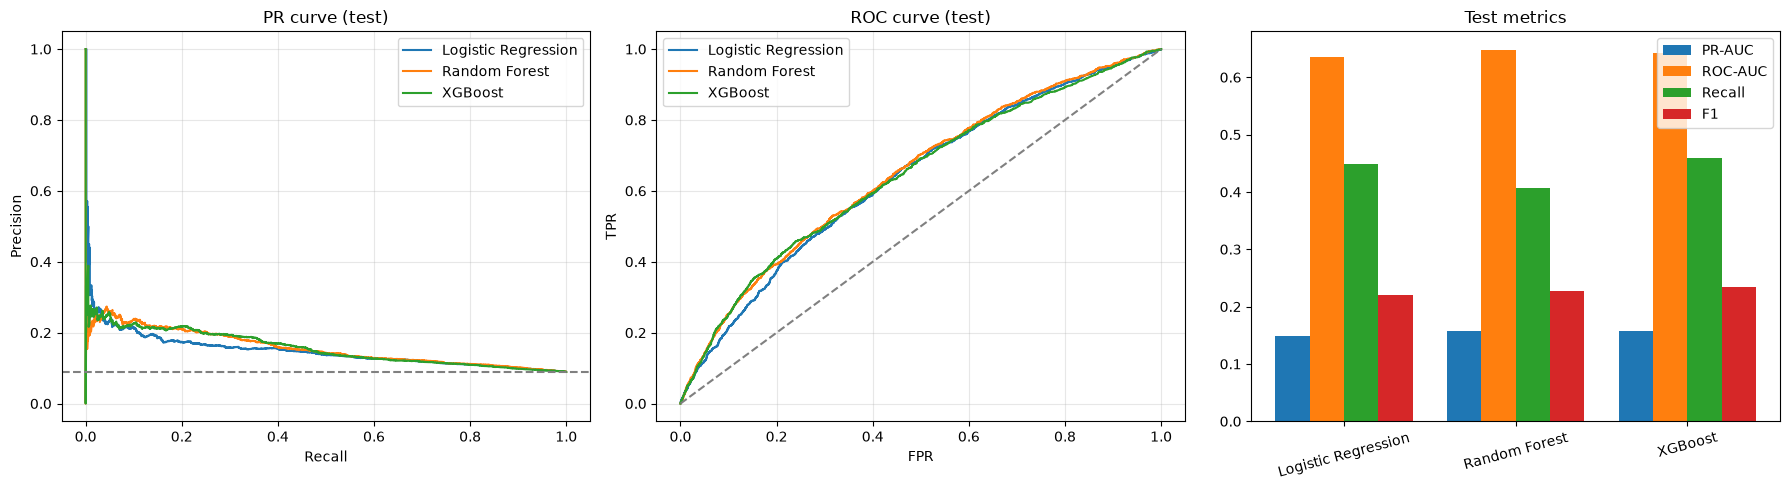

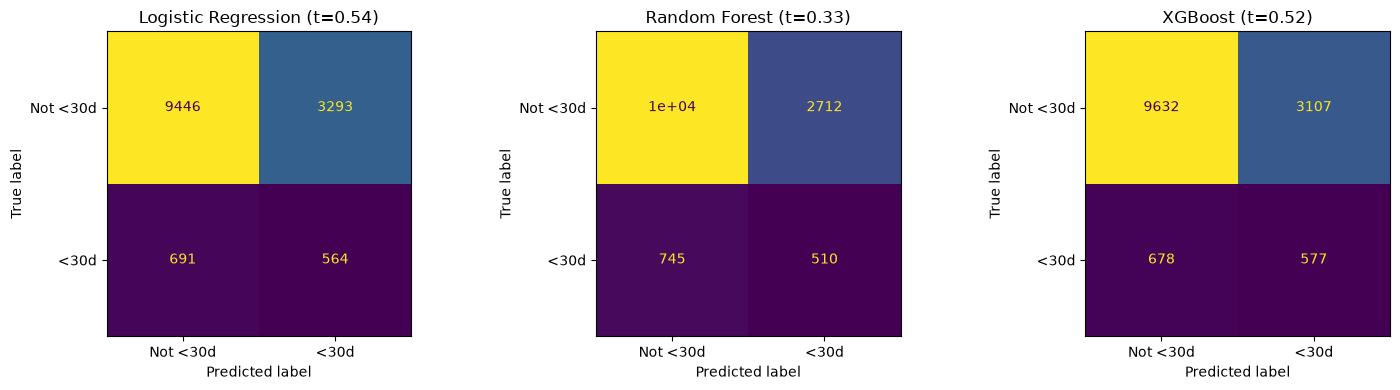

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for n in models:
    p, r, _ = precision_recall_curve(y_test, test_probs[n]); ax[0].plot(r, p, label=n)
    fpr, tpr, _ = roc_curve(y_test, test_probs[n]); ax[1].plot(fpr, tpr, label=n)
ax[0].axhline(y_test.mean(), ls="--", c="gray"); ax[0].set(xlabel="Recall", ylabel="Precision", title="PR curve (test)")
ax[1].plot([0,1],[0,1],"--",c="gray"); ax[1].set(xlabel="FPR", ylabel="TPR", title="ROC curve (test)")
for a in ax[:2]: a.legend(); a.grid(alpha=.3)
x = np.arange(len(models)); w = 0.2
for i, mname in enumerate(["PR-AUC","ROC-AUC","Recall","F1"]):
    ax[2].bar(x + i*w, test_df_res[mname], w, label=mname)
ax[2].set_xticks(x + 1.5*w); ax[2].set_xticklabels(models.keys(), rotation=15); ax[2].legend(); ax[2].set_title("Test metrics")
plt.tight_layout(); plt.savefig(f"{RESULTS}/baseline_models_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, n in zip(ax, models):
    cm = confusion_matrix(y_test, (test_probs[n] >= thr[n]).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Not <30d", "<30d"]).plot(ax=a, colorbar=False)
    a.set_title(f"{n} (t={thr[n]:.2f})")
plt.tight_layout(); plt.savefig(f"{RESULTS}/baseline_models_confusion.png", dpi=150); plt.show()

## Top features

Logistic regression is ranked by absolute coefficient on standardised features. The tree models use their built-in importances. These scales are different, so compare which features recur, not the magnitudes. Importances describe association in this dataset and are not causal effects.

In [6]:
imp = {
  "Logistic Regression": pd.Series(np.abs(fitted["Logistic Regression"].coef_[0]), index=X.columns),
  "Random Forest": pd.Series(fitted["Random Forest"].feature_importances_, index=X.columns),
  "XGBoost": pd.Series(fitted["XGBoost"].feature_importances_, index=X.columns),
}
top = pd.DataFrame({n: s.sort_values(ascending=False).head(10).index.tolist() for n, s in imp.items()})
top.index += 1; display(top)
top.to_csv(f"{RESULTS}/baseline_models_top_features.csv")

,Logistic Regression,Random Forest,XGBoost
1,discharge_group_Transferred,num_lab_procedures,discharge_group_Transferred
2,n_meds_on,num_medications,discharge_group_Home
3,discharge_group_Home,time_in_hospital,log1p_number_inpatient
4,repaglinide_Down,age_mid,number_inpatient
5,admission_type_Other,number_diagnoses,total_visits
6,log1p_total_visits,num_procedures,diag_1_group_Circulatory
7,diabetes_med,discharge_group_Transferred,diag_1_group_Musculoskeletal
8,number_outpatient,discharge_group_Home,race_Hispanic
9,number_inpatient,n_meds_on,payer_code_MC
10,diag_1_group_Circulatory,gender_male,diabetes_med


### Interpretation: features

The models agree on a few themes, which is more trustworthy than any single ranking:
- **Prior utilisation.** `number_inpatient`, `total_visits` and its log (and `number_outpatient` for logistic regression) appear for logistic regression and XGBoost. Past inpatient visits are the usual strongest predictor of readmission, and that holds here.
- **Discharge disposition.** `discharge_group_Transferred` and `discharge_group_Home` rank high for logistic regression and XGBoost, and also appear in the Random Forest top 10. Where the patient goes after discharge carries signal about severity and follow-up care.
- **Hospital stay intensity.** Random Forest's top features are `num_lab_procedures`, `num_medications`, `time_in_hospital` and `number_diagnoses`. These are continuous counts, which impurity-based importance tends to favour because they offer many split points. Treat that ranking with caution.
- **Diagnosis group.** The circulatory diagnosis group appears for logistic regression and XGBoost.

Caveats: the three importance measures are on different scales, impurity importance is biased toward high-cardinality and continuous features, and none of this is causal. For a stronger statement, use permutation importance on the validation set.

## Save results

Metrics are written to `results/` for the overall model comparison.

## Limitations

- **One split, one seed.** Differences of ~0.01 in PR-AUC or ROC-AUC between models are within what a different seed or split could change. No confidence intervals were computed, so do not over-interpret the ordering. Bootstrap CIs or repeated CV would be the next step.
- **Untuned baselines.** Each model could improve with tuning, so these are floors, not ceilings.
- **Threshold chosen on one validation split** of ~11k rows (~1,000 positives), so it is itself noisy.
- **Signal is weak overall.** All models land around ROC-AUC 0.63 to 0.65, which suggests the available features limit performance more than the choice of algorithm.

In [7]:
out = test_df_res.copy(); out.insert(1, "Split", "test")
v = val_df.copy(); v.insert(1, "Split", "validation")
pd.concat([v, out]).to_csv(f"{RESULTS}/baseline_models_metrics.csv", index=False)
default_df.to_csv(f"{RESULTS}/baseline_models_test_threshold05.csv", index=False)
print("saved to", RESULTS)

saved to ../results
